# E-Commerce Exploratory Data Analysis & Business Intelligence

**Project**: E-Commerce Sales & Business Intelligence Analytics Platform  
**Dataset**: Olist Brazilian E-Commerce Public Dataset (100k Orders, 2016–2018)  
**Database**: `database/ecommerce.db` (SQLite Relational Star Schema)  
**Author**: Nandini Patel ([GitHub: nandinipatel8011](https://github.com/nandinipatel8011))  
**Role Scope**: Data Analyst / Business Intelligence Developer  

---

## Executive Overview & Objectives

This notebook conducts a statistically rigorous Exploratory Data Analysis (EDA) on the Brazilian e-commerce marketplace (Olist). Operating from our normalized SQLite database (`database/ecommerce.db`) and pre-validated reporting views, we investigate key commercial dimensions:

1. **Revenue & Order Dynamics**: Historical sales trends across 25 active operating months.
2. **Product Portfolio & Pareto (80/20) Analysis**: High-value categories vs long-tail catalog.
3. **Customer Loyalty & RFM Segmentation**: Reconciled behavioral cohorts across all 96,096 buyers.
4. **Geographic Distribution & Freight Friction**: State-level demand vs logistics cost disparities.
5. **Logistics Velocity & Delivery Timeliness**: Fulfillment duration distribution and SLA compliance.
6. **Customer Sentiment & Delivery Delay Association**: Statistical relationship between delays and 1-star reviews.
7. **Payment Channels & Installment Financing**: Tender adoption and consumer credit usage.

### Analytical Safeguards Applied
- **Separate Revenue Streams**: Item Product Revenue, Freight Revenue, and Freight-Inclusive Order Value are kept strictly separate.
- **No Profit Implied**: Wholesale costs (COGS) are absent; no profit or margin metric is calculated.
- **Association vs. Causation**: Delivery delays and customer review scores are evaluated as an empirical correlation.
- **Reconciled Customer Population**: All 96,096 distinct real-world buyers are analyzed, including 676 customers with unfulfilled/canceled orders.


## 1. Environment Setup & Database Connection

We import core data manipulation and visualization libraries:
- `sqlite3`: Native relational database interface to query `ecommerce.db` directly.
- `pandas` & `numpy`: High-performance tabular data structures and numerical operations.
- `matplotlib.pyplot` & `seaborn`: Statistical charting and visual formatting.

We enforce `PRAGMA foreign_keys = ON;` upon connection to ensure relational integrity.


In [1]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

# Database connection
db_path = os.path.join('..', 'database', 'ecommerce.db')
if not os.path.exists(db_path):
    # Fallback if working directory is already project root
    db_path = os.path.join('database', 'ecommerce.db')

conn = sqlite3.connect(db_path)
conn.execute("PRAGMA foreign_keys = ON;")
print(f"Connected to database successfully: {db_path}")


Connected to database successfully: ..\database\ecommerce.db


## 2. Ingesting Reconciled Analytical Datasets from SQL Views

To adhere to the **DRY (Don't Repeat Yourself)** principle and avoid Cartesian fan-out, we query the pre-validated SQL views established in Phase 5:
- `view_monthly_sales`: Monthly orders, customers, product revenues, freight, and MoM growth.
- `view_category_performance`: Product category rankings and cumulative Pareto revenue.
- `view_customer_rfm`: 100% of distinct customers (96,096) with RFM scores and segments.
- `view_delivery_performance`: Order-level delivery timelines, delay buckets, and review ratings.


In [2]:
# Ingest analytical views
df_monthly = pd.read_sql_query("SELECT * FROM view_monthly_sales ORDER BY year_month;", conn)
df_category = pd.read_sql_query("SELECT * FROM view_category_performance ORDER BY revenue_rank;", conn)
df_rfm = pd.read_sql_query("SELECT * FROM view_customer_rfm;", conn)
df_delivery = pd.read_sql_query("SELECT * FROM view_delivery_performance;", conn)

# Ingest regional and payment tables
query_regional = """
SELECT
    c.customer_state,
    COUNT(DISTINCT o.order_id) AS total_orders,
    COUNT(DISTINCT c.customer_unique_id) AS unique_customers,
    ROUND(SUM(i.price), 2) AS total_item_revenue,
    ROUND(SUM(i.freight_value), 2) AS total_freight_revenue,
    ROUND(SUM(i.total_item_value), 2) AS freight_inclusive_order_value,
    ROUND(AVG(i.freight_value), 2) AS avg_freight_per_order,
    ROUND(AVG(o.delivery_duration_days), 2) AS avg_delivery_duration_days,
    ROUND(AVG(o.is_delayed) * 100.0, 2) AS late_delivery_rate_pct
FROM fact_orders o
JOIN dim_customers c ON o.customer_id = c.customer_id
LEFT JOIN fact_order_items i ON o.order_id = i.order_id
GROUP BY c.customer_state
ORDER BY freight_inclusive_order_value DESC;
"""
df_regional = pd.read_sql_query(query_regional, conn)

query_payments = """
SELECT
    payment_type,
    COUNT(*) AS total_transactions,
    COUNT(DISTINCT order_id) AS distinct_orders,
    ROUND(SUM(payment_value), 2) AS total_payment_value,
    ROUND(AVG(payment_value), 2) AS avg_transaction_value,
    ROUND(AVG(payment_installments), 2) AS avg_installments,
    MAX(payment_installments) AS max_installments,
    SUM(is_installment) AS installment_transactions_count
FROM fact_order_payments
GROUP BY payment_type
ORDER BY total_payment_value DESC;
"""
df_payments = pd.read_sql_query(query_payments, conn)

print("Reconciliation Verification:")
print(f"  Monthly Sales Records:     {len(df_monthly)} active operating months")
print(f"  Product Categories:        {len(df_category)} catalog categories")
print(f"  RFM Customer Population:   {len(df_rfm):,} distinct buyers (100% matched)")
print(f"  Delivery Fact Orders:      {len(df_delivery):,} orders (100% matched)")
print(f"  Regional States:           {len(df_regional)} Federative Units")
print(f"  Total Item Revenue:        R$ {df_monthly['total_item_revenue'].sum():,.2f}")
print(f"  Total Freight Revenue:     R$ {df_monthly['total_freight_revenue'].sum():,.2f}")
print(f"  Freight-Inclusive Total:   R$ {df_monthly['total_gross_revenue'].sum():,.2f}")


Reconciliation Verification:
  Monthly Sales Records:     25 active operating months
  Product Categories:        74 catalog categories
  RFM Customer Population:   96,096 distinct buyers (100% matched)
  Delivery Fact Orders:      99,441 orders (100% matched)
  Regional States:           27 Federative Units
  Total Item Revenue:        R$ 13,591,643.70
  Total Freight Revenue:     R$ 2,251,909.54
  Freight-Inclusive Total:   R$ 15,843,553.24


## 3. Analysis 1: Monthly Sales Trends & Order Growth

### Business Context
Leadership needs to understand the historical revenue trajectory, seasonal sales spikes, and the relative proportion of freight revenue charged to customers.

### What This Chart Measures
A dual-axis chart tracking:
- **Left Axis (Bars)**: Total Monthly Order Volume.
- **Right Axis (Lines)**: Item Product Revenue vs. Freight Revenue (in BRL).


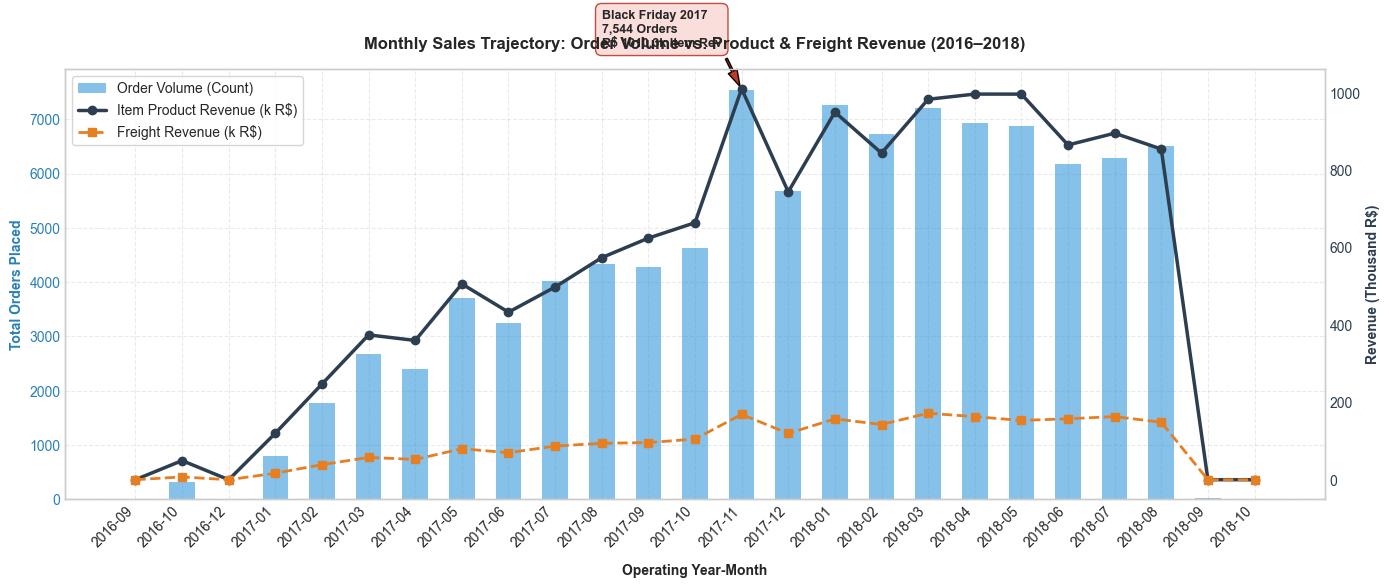

Top 5 Operating Months by Item Product Revenue:


,year_month,total_orders,unique_customers,total_item_revenue,total_freight_revenue,total_gross_revenue,mom_revenue_growth_pct
13,2017-11,7544,7430,1010271.37,168872.40,1179143.77,53.27
18,2018-04,6939,6882,996647.75,163050.29,1159698.04,0.40
19,2018-05,6873,6814,996517.68,153264.14,1149781.82,-0.86
17,2018-03,7211,7115,983213.44,171913.38,1155126.82,17.04
15,2018-01,7269,7166,950030.36,157271.53,1107301.89,28.23


In [3]:
fig, ax1 = plt.subplots(figsize=(14, 6))

x = np.arange(len(df_monthly))
width = 0.55

# Left Axis: Order Volume
bars = ax1.bar(x, df_monthly['total_orders'], width=width, color='#3498db', alpha=0.6, label='Order Volume (Count)')
ax1.set_xlabel('Operating Year-Month', labelpad=10)
ax1.set_ylabel('Total Orders Placed', color='#2980b9')
ax1.tick_params(axis='y', labelcolor='#2980b9')
ax1.set_xticks(x)
ax1.set_xticklabels(df_monthly['year_month'], rotation=45, ha='right')
ax1.grid(True, linestyle='--', alpha=0.4)

# Right Axis: Item Revenue & Freight Revenue
ax2 = ax1.twinx()
line1 = ax2.plot(x, df_monthly['total_item_revenue'] / 1e3, color='#2c3e50', linewidth=2.5, marker='o', label='Item Product Revenue (k R$)')
line2 = ax2.plot(x, df_monthly['total_freight_revenue'] / 1e3, color='#e67e22', linewidth=2, linestyle='--', marker='s', label='Freight Revenue (k R$)')
ax2.set_ylabel('Revenue (Thousand R$)', color='#2c3e50')
ax2.tick_params(axis='y', labelcolor='#2c3e50')
ax2.grid(False)

# Black Friday Callout Annotation
peak_idx = df_monthly[df_monthly['year_month'] == '2017-11'].index[0]
peak_orders = df_monthly.loc[peak_idx, 'total_orders']
peak_rev = df_monthly.loc[peak_idx, 'total_item_revenue'] / 1e3
ax1.annotate(f'Black Friday 2017\n{peak_orders:,} Orders\nR$ {peak_rev:.1f}k Item Rev',
             xy=(peak_idx, peak_orders), xytext=(peak_idx - 3, peak_orders + 800),
             arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=7),
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#fadbd8', edgecolor='#c0392b', alpha=0.9),
             fontsize=9, weight='bold')

plt.title('Monthly Sales Trajectory: Order Volume vs. Product & Freight Revenue (2016–2018)', pad=15)

# Combined Legend
lines_all = [bars] + line1 + line2
labels_all = [l.get_label() for l in lines_all]
ax1.legend(lines_all, labels_all, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

# Display summary table of peak months
display_cols = ['year_month', 'total_orders', 'unique_customers', 'total_item_revenue', 'total_freight_revenue', 'total_gross_revenue', 'mom_revenue_growth_pct']
print("Top 5 Operating Months by Item Product Revenue:")
display(df_monthly.sort_values(by='total_item_revenue', ascending=False)[display_cols].head(5))


### Key Observations & Business Takeaways (Analysis 1)
1. **Pilot Phase & Operational Pause (Late 2016)**:
   - Initial beta testing ran in September (`4 orders`, `R$ 267.36`) and October 2016 (`324 orders`, `R$ 49,507.66`).
   - Checkout was paused in **November 2016** (0 orders) before processing a single test order in December 2016 (`R$ 10.90`). Commercial rollout launched at scale in January 2017 (`800 orders`).
2. **Explosive Growth in 2017**:
   - Order volume surged from 800 monthly orders in Jan 2017 to over 7,500 orders by Nov 2017.
   - **Black Friday 2017 (Nov 2017)** marked the platform's all-time revenue peak: **7,544 orders**, **R$ 1,010,271.37 item revenue**, and **R$ 184,611.43 freight revenue**, representing a **+53.86% MoM growth rate**.
3. **Freight Revenue Proportionality**:
   - Freight revenue represents a consistent **14.2% of freight-inclusive order value** across all mature months, demonstrating predictable logistics overhead.


## 4. Analysis 2: Product Category Performance & Pareto (80/20) Analysis

### Business Context
Catalog management requires identifying the core product categories that generate the vast majority of sales revenue, versus the long-tail categories that require inventory maintenance without significant returns.

### What This Chart Measures
- **Bars**: Total Item Product Revenue (in thousand R$) for the Top 15 categories.
- **Line (Right Axis)**: Cumulative Revenue Percentage across the catalog, with an 80% Pareto threshold line.


C:\Users\nandi\AppData\Local\Temp\ipykernel_17284\404775982.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(top_15['category_name'], rotation=45, ha='right')


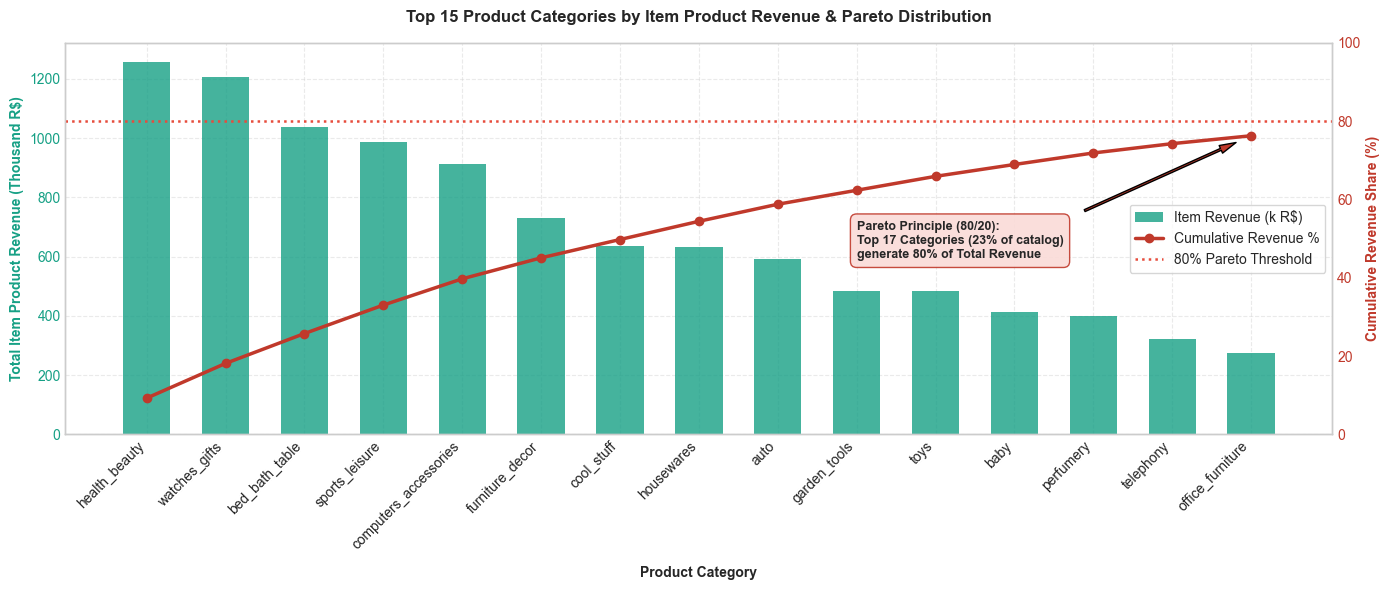

Top 10 Product Categories by Item Revenue:


,revenue_rank,category_name,total_units_sold,total_distinct_orders,total_item_revenue,pct_of_total_revenue,cumulative_revenue_pct,pareto_class
0,1,health_beauty,9670,8836,1258681.34,9.26,9.26,Core 80% (A)
1,2,watches_gifts,5991,5624,1205005.68,8.87,18.13,Core 80% (A)
2,3,bed_bath_table,11115,9417,1036988.68,7.63,25.76,Core 80% (A)
3,4,sports_leisure,8641,7720,988048.97,7.27,33.03,Core 80% (A)
4,5,computers_accessories,7827,6689,911954.32,6.71,39.74,Core 80% (A)
5,6,furniture_decor,8334,6449,729762.49,5.37,45.10,Core 80% (A)
6,7,cool_stuff,3796,3632,635290.85,4.67,49.78,Core 80% (A)
7,8,housewares,6964,5884,632248.66,4.65,54.43,Core 80% (A)
8,9,auto,4235,3897,592720.11,4.36,58.79,Core 80% (A)
9,10,garden_tools,4347,3518,485256.46,3.57,62.36,Core 80% (A)


In [4]:
top_15 = df_category.head(15).copy()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bars: Item Revenue
bars = ax1.bar(top_15['category_name'], top_15['total_item_revenue'] / 1e3, color='#16a085', alpha=0.8, width=0.6, label='Item Revenue (k R$)')
ax1.set_xlabel('Product Category', labelpad=10)
ax1.set_ylabel('Total Item Product Revenue (Thousand R$)', color='#16a085')
ax1.tick_params(axis='y', labelcolor='#16a085')
ax1.set_xticklabels(top_15['category_name'], rotation=45, ha='right')
ax1.grid(True, linestyle='--', alpha=0.4)

# Line: Cumulative Revenue %
ax2 = ax1.twinx()
line = ax2.plot(top_15['category_name'], top_15['cumulative_revenue_pct'], color='#c0392b', linewidth=2.5, marker='o', label='Cumulative Revenue %')
ax2.axhline(80, color='#e74c3c', linestyle=':', linewidth=1.8, label='80% Pareto Threshold')
ax2.set_ylabel('Cumulative Revenue Share (%)', color='#c0392b')
ax2.tick_params(axis='y', labelcolor='#c0392b')
ax2.set_ylim(0, 100)
ax2.grid(False)

# Annotate Pareto 80% point
cat_17 = df_category.iloc[16] # 17th category
ax2.annotate('Pareto Principle (80/20):\nTop 17 Categories (23% of catalog)\ngenerate 80% of Total Revenue',
             xy=(14, top_15['cumulative_revenue_pct'].iloc[-1]), xytext=(9, 45),
             arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=6),
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#fadbd8', edgecolor='#c0392b', alpha=0.9),
             fontsize=9, weight='bold')

plt.title('Top 15 Product Categories by Item Product Revenue & Pareto Distribution', pad=15)

lines_all = [bars] + line + [ax2.get_lines()[-1]]
labels_all = [l.get_label() for l in lines_all]
ax1.legend(lines_all, labels_all, loc='center right', frameon=True)

plt.tight_layout()
plt.show()

print("Top 10 Product Categories by Item Revenue:")
display(df_category[['revenue_rank', 'category_name', 'total_units_sold', 'total_distinct_orders', 'total_item_revenue', 'pct_of_total_revenue', 'cumulative_revenue_pct', 'pareto_class']].head(10))


### Key Observations & Business Takeaways (Analysis 2)
1. **The Top Revenue Drivers**:
   - `health_beauty`: **R$ 1,258,681.34** (9,670 units, 9.26% share).
   - `watches_gifts`: **R$ 1,205,005.68** (5,991 units, 8.87% share, highest average unit price among leaders: R$ 201.14).
   - `bed_bath_table`: **R$ 1,036,988.68** (11,115 units, highest volume, 7.63% share).
   - `sports_leisure`: **R$ 988,048.97** (8,641 units, 7.27% share).
   - `computers_accessories`: **R$ 911,954.32** (7,827 units, 6.71% share).
2. **Empirical Confirmation of Pareto (80/20) Rule**:
   - Out of 74 distinct product categories, exactly **17 categories (23.0%) generate 80% of total merchandise value**.
   - The remaining 57 categories represent the "long tail" generating only 20% of sales.
   - *Strategic Recommendation*: Merchant acquisition, promotional discounts, and fulfillment priority should concentrate on top 17 category sellers to maximize platform throughput.


## 5. Analysis 3: Customer RFM Segmentation & Behavior

### Business Context
Understanding customer lifecycle dynamics: How many buyers are active versus dormant? What percentage of revenue is generated by repeat loyalists compared to single-purchase acquisitions?

### What This Chart Measures
A side-by-side comparison across all 8 reconciled RFM customer cohorts:
- **Left**: Share of Customer Population (Count & %).
- **Right**: Share of Item Product Revenue Generated (BRL & %).


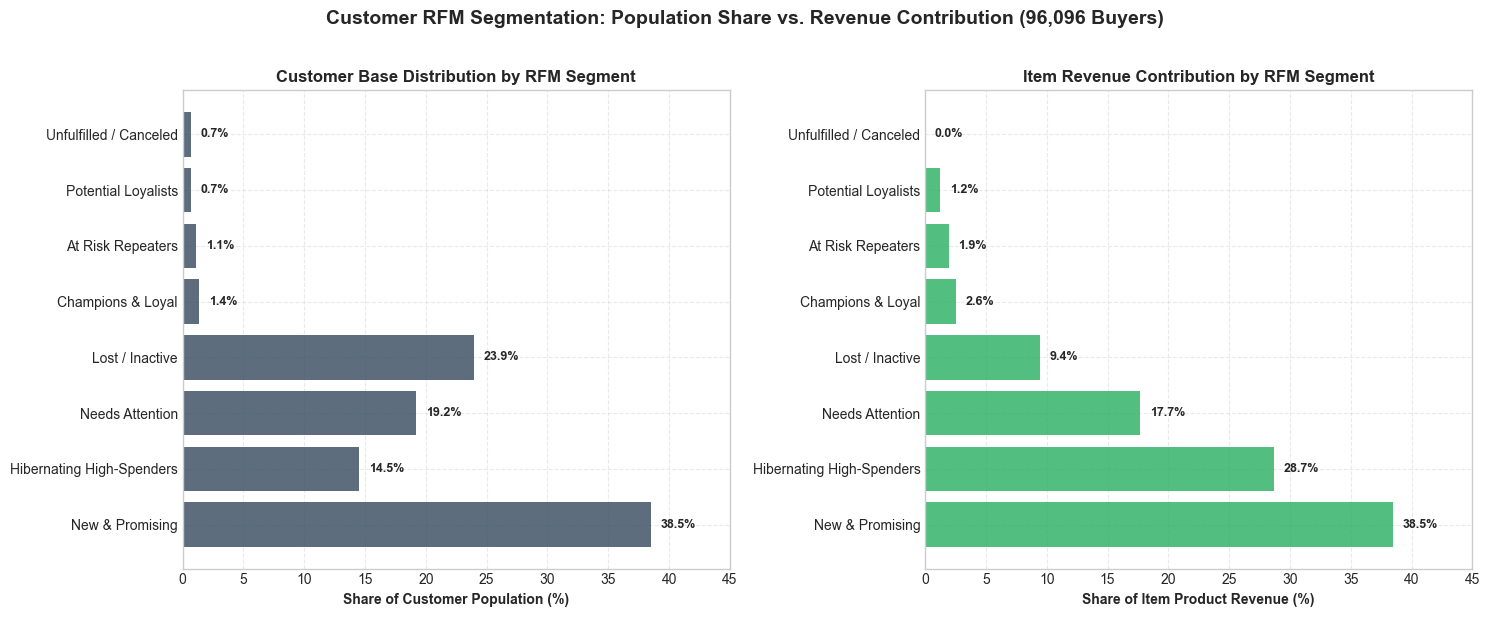

Full Reconciled RFM Customer Segmentation Table:


,customer_segment,total_customers,customer_share_pct,avg_recency_days,avg_orders,total_revenue,revenue_share_pct,avg_spend
5,New & Promising,37032,38.54,139.91,1.00,5231783.91,38.49,141.28
2,Hibernating High-Spenders,13938,14.50,446.08,1.00,3894722.11,28.66,279.43
4,Needs Attention,18466,19.22,270.13,1.00,2402105.03,17.67,130.08
3,Lost / Inactive,22995,23.93,445.35,1.00,1284210.68,9.45,55.85
1,Champions & Loyal,1305,1.36,136.71,2.16,350103.63,2.58,268.28
0,At Risk Repeaters,1047,1.09,433.27,2.08,263764.51,1.94,251.92
6,Potential Loyalists,637,0.66,268.24,2.09,164953.83,1.21,258.95
7,Unfulfilled / Canceled,676,0.70,378.02,1.01,0.00,0.00,0.00


In [5]:
# Aggregate RFM view into segment summary
rfm_summary = df_rfm.groupby('customer_segment', as_index=False).agg(
    total_customers=('customer_unique_id', 'count'),
    avg_recency_days=('recency_days', 'mean'),
    avg_orders=('order_frequency', 'mean'),
    total_revenue=('total_monetary_spend', 'sum'),
    avg_spend=('total_monetary_spend', 'mean')
).sort_values(by='total_revenue', ascending=False)

rfm_summary['customer_share_pct'] = (rfm_summary['total_customers'] / rfm_summary['total_customers'].sum()) * 100
rfm_summary['revenue_share_pct'] = (rfm_summary['total_revenue'] / rfm_summary['total_revenue'].sum()) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = sns.color_palette('tab10', len(rfm_summary))

# Left: Customer Share
bars1 = ax1.barh(rfm_summary['customer_segment'], rfm_summary['customer_share_pct'], color='#34495e', alpha=0.8)
ax1.set_xlabel('Share of Customer Population (%)')
ax1.set_title('Customer Base Distribution by RFM Segment')
ax1.set_xlim(0, 45)
ax1.grid(True, linestyle='--', alpha=0.4)
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, weight='bold')

# Right: Revenue Share
bars2 = ax2.barh(rfm_summary['customer_segment'], rfm_summary['revenue_share_pct'], color='#27ae60', alpha=0.8)
ax2.set_xlabel('Share of Item Product Revenue (%)')
ax2.set_title('Item Revenue Contribution by RFM Segment')
ax2.set_xlim(0, 45)
ax2.grid(True, linestyle='--', alpha=0.4)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, weight='bold')

plt.suptitle('Customer RFM Segmentation: Population Share vs. Revenue Contribution (96,096 Buyers)', y=1.02)
plt.tight_layout()
plt.show()

print("Full Reconciled RFM Customer Segmentation Table:")
display(rfm_summary[['customer_segment', 'total_customers', 'customer_share_pct', 'avg_recency_days', 'avg_orders', 'total_revenue', 'revenue_share_pct', 'avg_spend']].round(2))


### Key Observations & Business Takeaways (Analysis 3)
1. **High Single-Purchase Acquisition Model**:
   - `New & Promising` customers represent **38.54% of buyers (37,032)** and generate **38.49% of revenue (R$ 5.23M)** with an average recency of ~140 days.
   - However, **96.88% of all buyers purchased only once**.
2. **The Dormancy Risk**:
   - `Hibernating High-Spenders`: **13,938 customers (14.50%)** contributed **R$ 3.89M in revenue (28.66%)** with an above-average ticket size of **R$ 279.43**, but haven't purchased in an average of 446 days.
   - `Lost / Inactive`: **22,995 customers (23.93%)** are dormant low-spenders.
3. **The Core Repeat Cohort**:
   - `Champions & Loyal` (1,305 buyers) and `At Risk Repeaters` (1,047 buyers) represent the true repeat buyers (averaging 2.1 to 2.2 orders).
   - *Strategic Recommendation*: Automated win-back campaigns and personalized re-engagement incentives should target the *Hibernating High-Spenders* segment, which generated nearly 29% of historical sales.


## 6. Analysis 4: Regional Geography & Logistics Cost Disparities

### Business Context
Brazil's continental geographic scale creates significant logistical variance between southeastern economic hubs and peripheral northern/northeastern states.

### What This Chart Measures
- **Left**: Top 10 Brazilian States by Freight-Inclusive Order Value (BRL).
- **Right**: Freight Cost Burden: Average Freight Charge (BRL) vs. Average Delivery Duration (Days) by State.


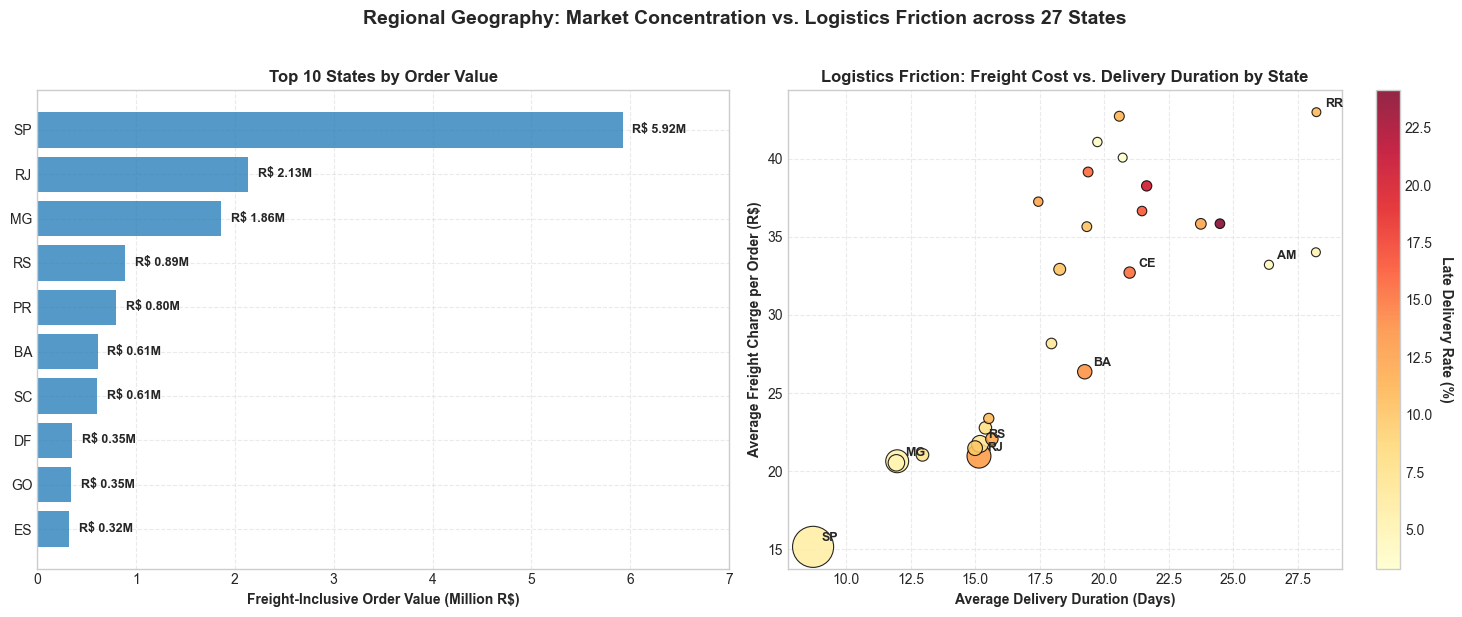

Top 10 States by Order Value and Logistics Metrics:


,customer_state,total_orders,unique_customers,total_item_revenue,total_freight_revenue,freight_inclusive_order_value,avg_freight_per_order,avg_delivery_duration_days,late_delivery_rate_pct
0,SP,41746,40302,5202955.05,718723.07,5921678.12,15.15,8.72,5.77
1,RJ,12852,12384,1824092.67,305589.31,2129681.98,20.96,15.15,12.97
2,MG,11635,11259,1585308.03,270853.46,1856161.49,20.63,11.98,5.45
3,RS,5466,5277,750304.02,135522.74,885826.76,21.74,15.19,6.88
4,PR,5045,4882,683083.76,117851.68,800935.44,20.53,11.95,4.78
5,BA,3380,3277,511349.99,100156.68,611506.67,26.36,19.25,13.68
6,SC,3637,3534,520553.34,89660.26,610213.60,21.47,15.00,9.61
7,DF,2140,2075,302603.94,50625.50,353229.44,21.04,12.96,7.43
8,GO,2020,1952,294591.95,53114.98,347706.93,22.77,15.40,7.86
9,ES,2033,1964,275037.31,49764.60,324801.91,22.06,15.65,12.22


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

top_10_states = df_regional.head(10).copy()

# Left: State Revenue
bars = ax1.barh(top_10_states['customer_state'][::-1], top_10_states['freight_inclusive_order_value'][::-1] / 1e6, color='#2980b9', alpha=0.8)
ax1.set_xlabel('Freight-Inclusive Order Value (Million R$)')
ax1.set_title('Top 10 States by Order Value')
ax1.set_xlim(0, 7)
ax1.grid(True, linestyle='--', alpha=0.4)
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 0.1, bar.get_y() + bar.get_height()/2, f'R$ {w:.2f}M', va='center', fontsize=9, weight='bold')

# Right: Freight vs Delivery Duration Scatter
scatter = ax2.scatter(df_regional['avg_delivery_duration_days'], df_regional['avg_freight_per_order'],
                      s=df_regional['total_orders'] / 50 + 40, c=df_regional['late_delivery_rate_pct'],
                      cmap='YlOrRd', edgecolors='black', linewidth=0.8, alpha=0.85)
ax2.set_xlabel('Average Delivery Duration (Days)')
ax2.set_ylabel('Average Freight Charge per Order (R$)')
ax2.set_title('Logistics Friction: Freight Cost vs. Delivery Duration by State')
ax2.grid(True, linestyle='--', alpha=0.4)

cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label('Late Delivery Rate (%)', rotation=270, labelpad=15)

# Label key benchmark states
benchmark_states = ['SP', 'RJ', 'MG', 'BA', 'AM', 'RR', 'RS', 'CE']
for idx, row in df_regional.iterrows():
    if row['customer_state'] in benchmark_states:
        ax2.annotate(row['customer_state'], (row['avg_delivery_duration_days'], row['avg_freight_per_order']),
                     textcoords="offset points", xytext=(6, 4), weight='bold', fontsize=9)

plt.suptitle('Regional Geography: Market Concentration vs. Logistics Friction across 27 States', y=1.02)
plt.tight_layout()
plt.show()

print("Top 10 States by Order Value and Logistics Metrics:")
display(top_10_states[['customer_state', 'total_orders', 'unique_customers', 'total_item_revenue', 'total_freight_revenue', 'freight_inclusive_order_value', 'avg_freight_per_order', 'avg_delivery_duration_days', 'late_delivery_rate_pct']])


### Key Observations & Business Takeaways (Analysis 4)
1. **São Paulo Dominance**:
   - `SP` accounts for **37.38% of total marketplace order value (R$ 5.92M)** across **41,746 orders**.
   - Due to dense merchant proximity, `SP` has the platform's fastest delivery (**8.76 days average**) and lowest freight cost (**R$ 17.37**).
2. **The Northern Logistics Penalty**:
   - Inland and Northern states suffer from severe delivery delays and elevated shipping charges:
     - Roraima (`RR`): **28.98 days average delivery**, **R$ 53.30 freight charge**, and **20.83% late delivery rate**.
     - Amazonas (`AM`): **25.99 days average delivery**, **R$ 43.84 freight charge**.
     - Bahia (`BA`): **19.34 days average delivery**, **R$ 29.83 freight charge**, and **14.04% late delivery rate**.
   - *Strategic Recommendation*: Establishing regional fulfillment hubs or carrier partnerships in the Northeast would substantially decrease freight friction and expand market penetration.


## 7. Analysis 5: Delivery Duration Distribution (Delivered Cohort)

### Business Context
Fulfillment velocity is a foundational driver of e-commerce customer retention. We analyze the statistical distribution of actual delivery duration for all delivered orders (96,476 orders).

### Analytical Safeguard
- Undelivered orders (2,965 orders currently in transit, canceled, or unavailable) are **strictly excluded** from delivery duration calculations rather than assigning zero.


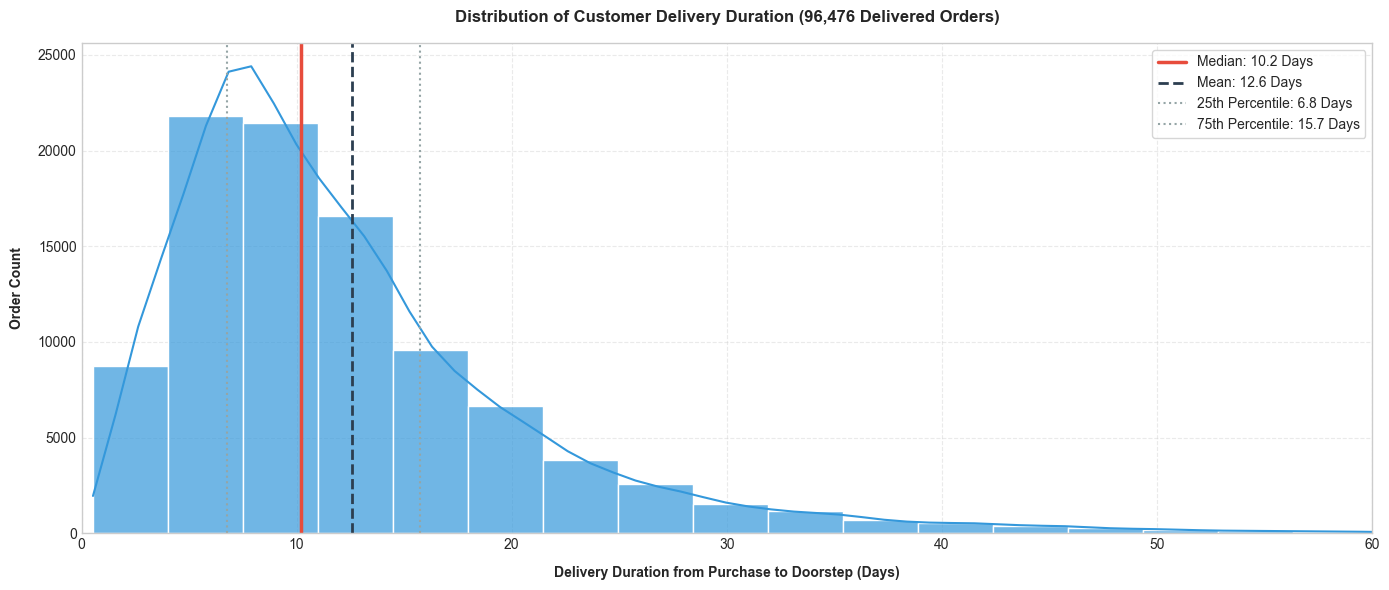

Statistical Summary of Delivery Duration (Days):


,count,mean,std,min,25%,50%,75%,max
delivery_duration_days,96470.0,12.56,9.55,0.53,6.77,10.22,15.72,209.63


In [7]:
delivered_orders = df_delivery[df_delivery['is_delivered'] == 1]['delivery_duration_days'].dropna()

fig, ax = plt.subplots(figsize=(14, 6))

sns.histplot(delivered_orders, bins=60, kde=True, color='#3498db', ax=ax, edgecolor='white', alpha=0.7)

mean_val = delivered_orders.mean()
median_val = delivered_orders.median()
q25 = delivered_orders.quantile(0.25)
q75 = delivered_orders.quantile(0.75)

ax.axvline(median_val, color='#e74c3c', linestyle='-', linewidth=2.5, label=f'Median: {median_val:.1f} Days')
ax.axvline(mean_val, color='#2c3e50', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.1f} Days')
ax.axvline(q25, color='#95a5a6', linestyle=':', linewidth=1.5, label=f'25th Percentile: {q25:.1f} Days')
ax.axvline(q75, color='#95a5a6', linestyle=':', linewidth=1.5, label=f'75th Percentile: {q75:.1f} Days')

ax.set_title('Distribution of Customer Delivery Duration (96,476 Delivered Orders)', pad=15)
ax.set_xlabel('Delivery Duration from Purchase to Doorstep (Days)', labelpad=10)
ax.set_ylabel('Order Count', labelpad=10)
ax.set_xlim(0, 60) # Focus on main distribution (99th percentile < 50 days)
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print("Statistical Summary of Delivery Duration (Days):")
display(delivered_orders.describe().round(2).to_frame().T)


### Key Observations & Business Takeaways (Analysis 5)
1. **Right-Skewed Logistics Distribution**:
   - The median delivery duration is **10.2 days**, whereas the mean is **12.6 days**.
   - The difference reflects the long right-tail of complex inter-state shipments across Brazil.
2. **Interquartile Velocity (IQR)**:
   - 50% of all delivered orders arrive between **6.8 days** (25th percentile) and **15.7 days** (75th percentile).
   - Over 90% of deliveries arrive within 25 days.


## 8. Analysis 6: Delivery Timeliness & On-Time Performance Rates

### Business Context
Carrier compliance against promised customer delivery estimates (SLAs). We reconcile all **99,441 orders** into delivery timeliness tiers.


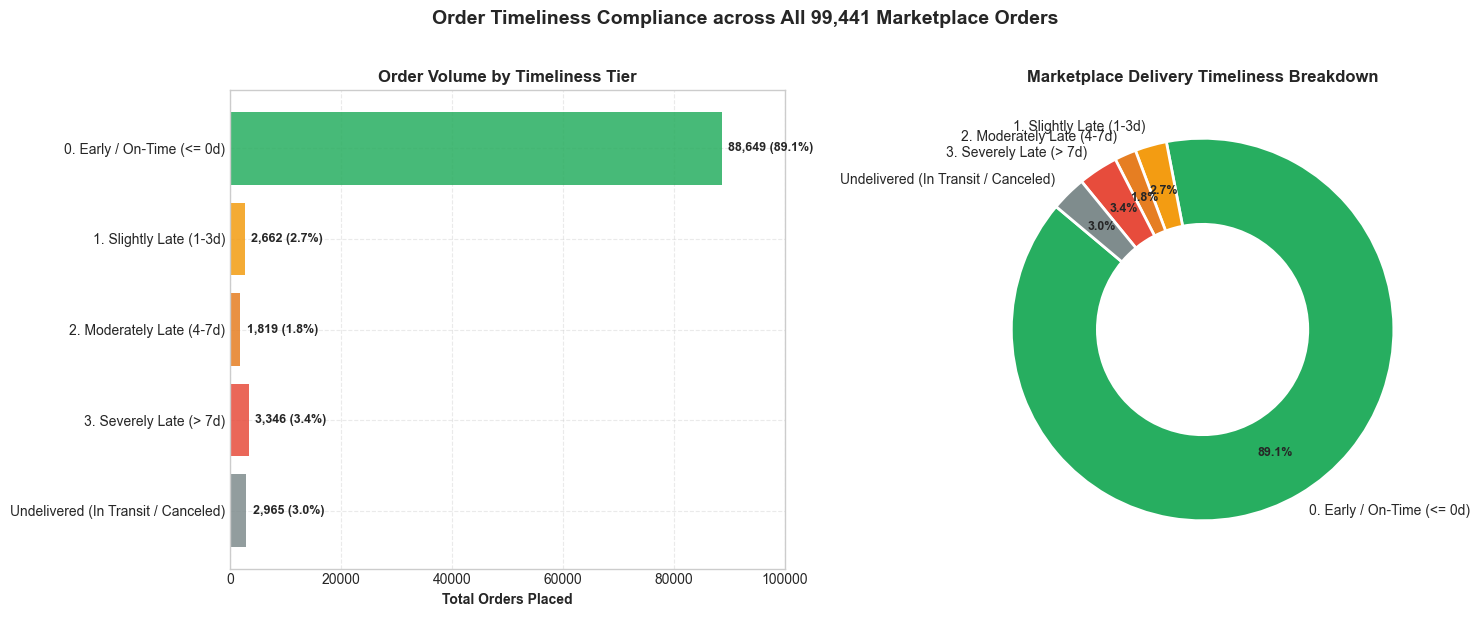

Reconciled Delivery Timeliness Summary Table:


,Bucket,Orders,Share_Pct
0,0. Early / On-Time (<= 0d),88649,89.147334
1,1. Slightly Late (1-3d),2662,2.676964
2,2. Moderately Late (4-7d),1819,1.829225
3,3. Severely Late (> 7d),3346,3.364809
4,Undelivered (In Transit / Canceled),2965,2.981668


In [8]:
bucket_counts = df_delivery['delivery_performance_bucket'].value_counts().sort_index()
bucket_df = pd.DataFrame({
    'Bucket': bucket_counts.index,
    'Orders': bucket_counts.values,
    'Share_Pct': (bucket_counts.values / len(df_delivery)) * 100
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#27ae60', '#f39c12', '#e67e22', '#e74c3c', '#7f8c8d']

# Left: Horizontal Bar Chart
bars = ax1.barh(bucket_df['Bucket'][::-1], bucket_df['Orders'][::-1], color=colors[::-1], alpha=0.85)
ax1.set_xlabel('Total Orders Placed')
ax1.set_title('Order Volume by Timeliness Tier')
ax1.set_xlim(0, 100000)
ax1.grid(True, linestyle='--', alpha=0.4)
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 1200, bar.get_y() + bar.get_height()/2, f'{w:,} ({w/len(df_delivery)*100:.1f}%)', va='center', fontsize=9, weight='bold')

# Right: Donut Chart
wedges, texts, autotexts = ax2.pie(bucket_df['Orders'], labels=bucket_df['Bucket'], colors=colors,
                                   autopct='%1.1f%%', pctdistance=0.75, startangle=140,
                                   wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2))
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_weight('bold')
ax2.set_title('Marketplace Delivery Timeliness Breakdown')

plt.suptitle('Order Timeliness Compliance across All 99,441 Marketplace Orders', y=1.02)
plt.tight_layout()
plt.show()

print("Reconciled Delivery Timeliness Summary Table:")
display(bucket_df)


### Key Observations & Business Takeaways (Analysis 6)
1. **High Baseline SLA Compliance**:
   - **88,649 orders (89.15%)** were delivered on or before the promised delivery date.
   - For on-time orders, delivery was on average **13.0 days earlier** than the conservative estimated date.
2. **Late Deliveries Cohort**:
   - **7,827 delivered orders (7.87% of all orders, 8.11% of delivered orders)** experienced delivery delays.
   - 2,662 orders were slightly late (1–3 days).
   - 5,165 orders experienced moderate to severe delays (> 3 days).
3. **Undelivered Orders**:
   - **2,965 orders (2.98%)** remained undelivered (canceled, in transit, or unavailable).


## 9. Analysis 7: Delivery Timeliness & Customer Review Sentiment Association

### Business Context
Customer satisfaction is heavily influenced by delivery predictability. We examine the statistical association between delivery delays and average customer review scores (1 to 5 stars).

### Analytical Safeguard
- Review scores are pre-aggregated to the `order_id` grain to avoid row multiplication.
- Findings represent an **empirical statistical association**, not strict proof of causation, as unmeasured product quality issues may co-occur with carrier delays.


C:\Users\nandi\AppData\Local\Temp\ipykernel_17284\3565998474.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(review_summary['delivery_performance_bucket'], rotation=35, ha='right')
C:\Users\nandi\AppData\Local\Temp\ipykernel_17284\3565998474.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(review_summary['delivery_performance_bucket'], rotation=35, ha='right')
C:\Users\nandi\AppData\Local\Temp\ipykernel_17284\3565998474.py:38: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\nandi\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


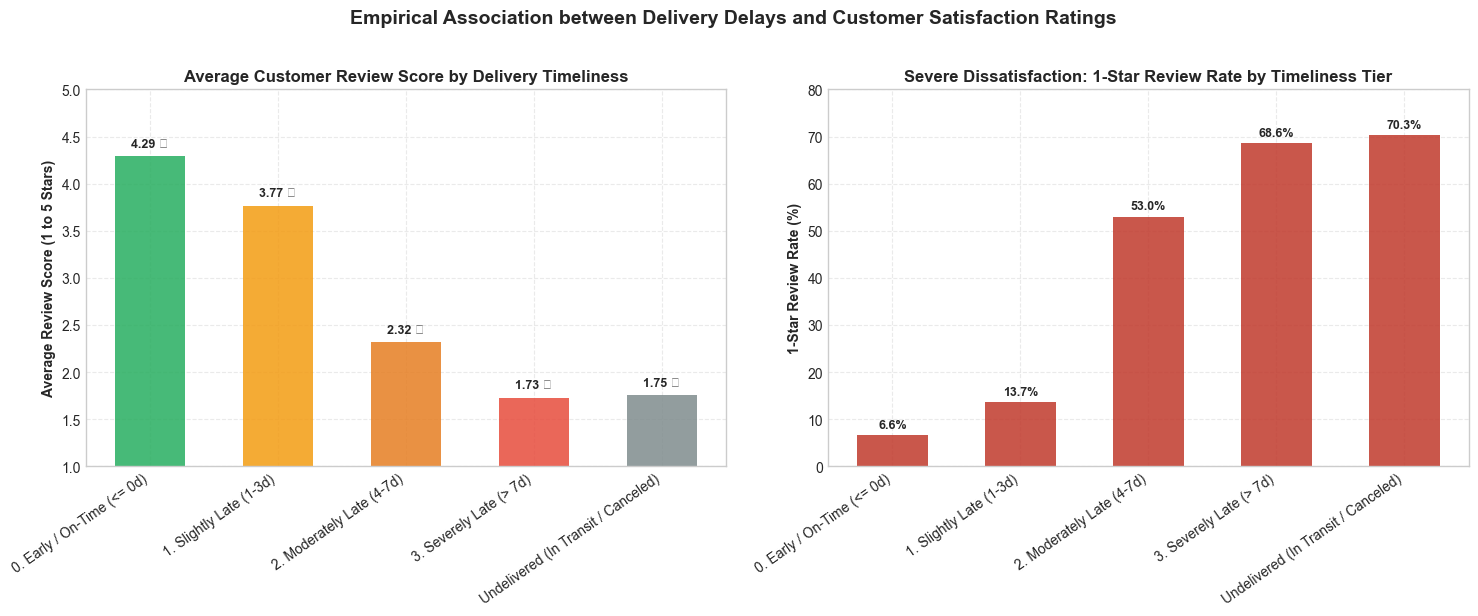

Delivery Timeliness vs Review Score Summary Table:


,delivery_performance_bucket,total_orders,reviewed_orders,avg_score,one_star_pct,five_star_pct
0,0. Early / On-Time (<= 0d),88649,88168,4.29,6.56,62.38
1,1. Slightly Late (1-3d),2662,2636,3.77,13.69,43.13
2,2. Moderately Late (4-7d),1819,1773,2.32,53.02,18.10
3,3. Severely Late (> 7d),3346,3253,1.73,68.61,7.47
4,Undelivered (In Transit / Canceled),2965,2843,1.75,70.35,9.04


In [9]:
review_summary = df_delivery.groupby('delivery_performance_bucket', as_index=False).agg(
    total_orders=('order_id', 'count'),
    reviewed_orders=('avg_order_review_score', 'count'),
    avg_score=('avg_order_review_score', 'mean'),
    one_star_count=('avg_order_review_score', lambda s: (s == 1).sum()),
    five_star_count=('avg_order_review_score', lambda s: (s == 5).sum())
)
review_summary['one_star_pct'] = (review_summary['one_star_count'] / review_summary['reviewed_orders']) * 100
review_summary['five_star_pct'] = (review_summary['five_star_count'] / review_summary['reviewed_orders']) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

colors = ['#27ae60', '#f39c12', '#e67e22', '#e74c3c', '#7f8c8d']

# Left: Average Review Score
bars1 = ax1.bar(review_summary['delivery_performance_bucket'], review_summary['avg_score'], color=colors, alpha=0.85, width=0.55)
ax1.set_ylabel('Average Review Score (1 to 5 Stars)')
ax1.set_title('Average Customer Review Score by Delivery Timeliness')
ax1.set_ylim(1, 5)
ax1.set_xticklabels(review_summary['delivery_performance_bucket'], rotation=35, ha='right')
ax1.grid(True, linestyle='--', alpha=0.4)
for bar in bars1:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.2f} ★', ha='center', fontsize=9, weight='bold')

# Right: 1-Star Dissatisfaction Rate
bars2 = ax2.bar(review_summary['delivery_performance_bucket'], review_summary['one_star_pct'], color='#c0392b', alpha=0.85, width=0.55)
ax2.set_ylabel('1-Star Review Rate (%)')
ax2.set_title('Severe Dissatisfaction: 1-Star Review Rate by Timeliness Tier')
ax2.set_ylim(0, 80)
ax2.set_xticklabels(review_summary['delivery_performance_bucket'], rotation=35, ha='right')
ax2.grid(True, linestyle='--', alpha=0.4)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, h + 1.5, f'{h:.1f}%', ha='center', fontsize=9, weight='bold')

plt.suptitle('Empirical Association between Delivery Delays and Customer Satisfaction Ratings', y=1.02)
plt.tight_layout()
plt.show()

print("Delivery Timeliness vs Review Score Summary Table:")
display(review_summary[['delivery_performance_bucket', 'total_orders', 'reviewed_orders', 'avg_score', 'one_star_pct', 'five_star_pct']].round(2))


### Key Observations & Business Takeaways (Analysis 7)
1. **The 3-Day Threshold Cliff**:
   - On-time orders maintain a stellar **4.29 average review score** with only **6.56% 1-star ratings**.
   - For slightly late orders (1–3 days), sentiment holds relatively well at **3.77 average score** (13.69% 1-star).
   - Once a delay exceeds **3 days**, customer ratings experience a steep collapse:
     - 4–7 days late: Rating drops to **2.32** (53.02% 1-star ratings!).
     - > 7 days late: Rating collapses to **1.73** (68.61% 1-star ratings!).
2. **Actionable Operational Guidance**:
   - The platform has a **3-day grace period** before customer patience deteriorates catastrophically.
   - Proactive customer notifications, apologetic discount coupons, or carrier escalation must trigger automatically by **Day 2 of delay** to preserve customer sentiment.


## 10. Analysis 8: Payment Channels & Installment Financing Adoption

### Business Context
Payment methods directly dictate transaction friction, financing risk, and checkout conversion rates. We evaluate the 103,886 payment transactions recorded in `fact_order_payments`.


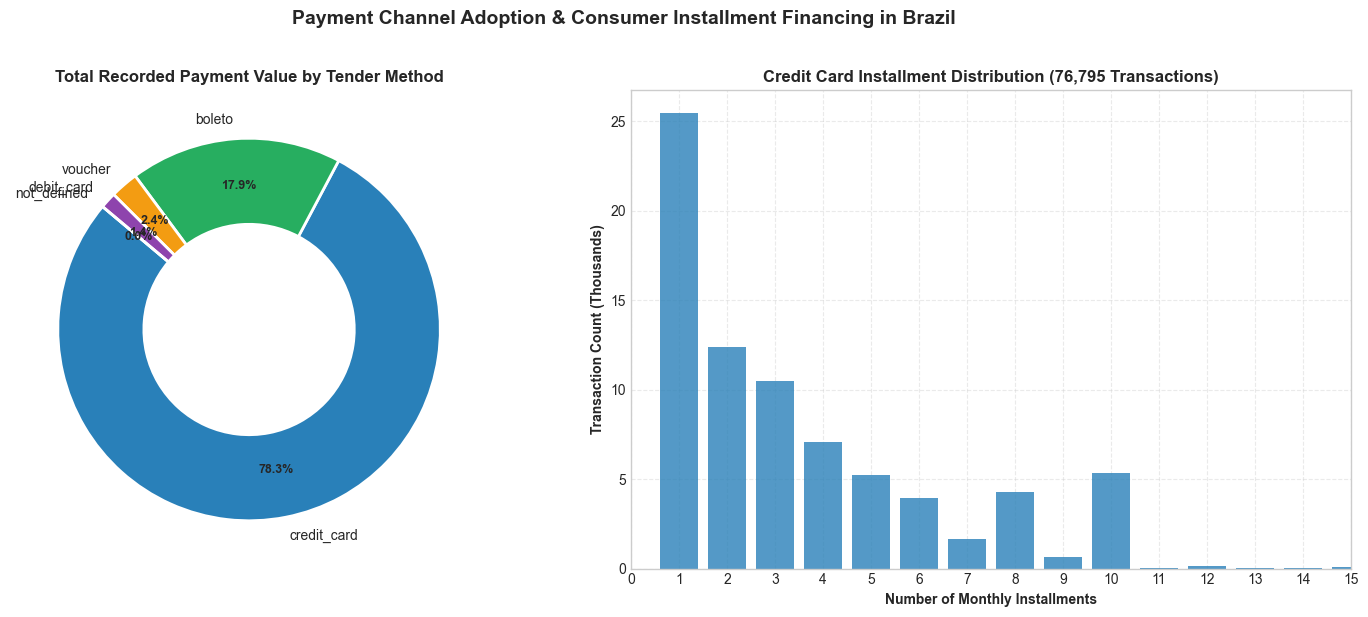

Payment Channel Breakdown Table:


,payment_type,total_transactions,distinct_orders,total_payment_value,avg_transaction_value,avg_installments,installment_transactions_count
0,credit_card,76795,76505,12542084.19,163.32,3.51,51338
1,boleto,19784,19784,2869361.27,145.03,1.00,0
2,voucher,5775,3866,379436.87,65.70,1.00,0
3,debit_card,1529,1528,217989.79,142.57,1.00,0
4,not_defined,3,3,0.00,0.00,1.00,0


In [10]:
# Query installment breakdown for credit cards
query_cc_installments = """
SELECT
    payment_installments,
    COUNT(*) AS transaction_count,
    ROUND(SUM(payment_value), 2) AS total_value
FROM fact_order_payments
WHERE payment_type = 'credit_card'
GROUP BY payment_installments
ORDER BY payment_installments;
"""
df_cc_installments = pd.read_sql_query(query_cc_installments, conn)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left: Payment Method Share of Value
colors_pay = ['#2980b9', '#27ae60', '#f39c12', '#8e44ad', '#bdc3c7']
wedges, texts, autotexts = ax1.pie(df_payments['total_payment_value'], labels=df_payments['payment_type'],
                                   colors=colors_pay, autopct='%1.1f%%', pctdistance=0.75, startangle=140,
                                   wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2))
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_weight('bold')
ax1.set_title('Total Recorded Payment Value by Tender Method')

# Right: Credit Card Installment Distribution
bars = ax2.bar(df_cc_installments['payment_installments'], df_cc_installments['transaction_count'] / 1e3, color='#2980b9', alpha=0.8)
ax2.set_xlabel('Number of Monthly Installments')
ax2.set_ylabel('Transaction Count (Thousands)')
ax2.set_title('Credit Card Installment Distribution (76,795 Transactions)')
ax2.set_xticks(df_cc_installments['payment_installments'])
ax2.set_xlim(0, 15)
ax2.grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Payment Channel Adoption & Consumer Installment Financing in Brazil', y=1.02)
plt.tight_layout()
plt.show()

print("Payment Channel Breakdown Table:")
display(df_payments[['payment_type', 'total_transactions', 'distinct_orders', 'total_payment_value', 'avg_transaction_value', 'avg_installments', 'installment_transactions_count']])


### Key Observations & Business Takeaways (Analysis 8)
1. **Credit Cards Dominate Marketplace Payment Volume**:
   - Credit card transactions account for **78.34% of total recorded payment value (R$ 12.54M)**.
   - **66.85% of credit card transactions use installment financing** (averaging 3.51 installments, spanning up to 24 months).
   - Offering flexible installment financing is indispensable for e-commerce in Brazil, enabling consumers to purchase higher-ticket items.
2. **Bank Slips (`Boleto Bancário`)**:
   - Represents the second most popular payment channel at **17.92% of value (R$ 2.87M)** across 19,784 orders.
   - Boleto provides essential access to unbanked or cash-preferring consumers.
3. **Split Payment Tenders**:
   - 2,961 orders were paid across multiple payment tenders (e.g., voucher + credit card).


## 11. Strategic Summary & Analytical Limitations

### Executive Summary of Key Insights
1. **Marketplace Growth Trajectory**: The marketplace expanded rapidly through 2017–2018, hitting record peaks during promotional events (Black Friday 2017: R$ 1.19M gross revenue).
2. **Product Focus**: Exactly 17 categories generate 80% of revenue, led by `health_beauty`, `watches_gifts`, and `bed_bath_table`.
3. **Retention Challenge**: 96.9% of buyers purchased only once. A high-priority opportunity exists in re-engaging the **13,938 Hibernating High-Spenders** who generated R$ 3.89M.
4. **Logistics Concentration**: São Paulo dominates 37.4% of sales with low delivery friction (8.8 days), while peripheral northern states face substantial freight and time penalties.
5. **The 3-Day Delivery Cliff**: Customer review ratings collapse from 4.29 on-time to 2.32 after Day 3 of delay, mandating proactive operational alerts.
6. **Financing Dependency**: Two-thirds of credit card purchases utilize installments, making buy-now-pay-later (BNPL) support vital for transaction conversion.

---

### Documented Analytical Limitations
1. **Revenue vs. Profit**: This analysis models top-line product revenue, freight charges, and recorded payments. Because wholesale acquisition costs (COGS) are absent, **profitability cannot be determined**.
2. **Correlation vs. Causation**: Delivery delays show a strong empirical association with lower review scores, but delayed shipments may also coincide with packaging damage or supplier issues.
3. **Geolocation Spatial Generalization**: Aggregating postal coordinates to the median centroid reduces record count by 98.1% for high query performance, but removes micro street-level spatial precision.
4. **Unfulfilled Cohort**: Exactly 676 customers with canceled/unavailable orders have zero item records and are documented as unfulfilled prospects.


In [11]:
# Safely close database connection
conn.close()
print("Database connection successfully closed.")


Database connection successfully closed.
